In [25]:
import numpy as np
import scipy as sp
import scipy.optimize

import matplotlib.pyplot as plt

strQx = "qx_US.txt"
strQy = "qy_US.txt"
strNx = "besta_US.txt"

strQx = "CH_qx.txt"
strQy = "CH_qy.txt"
strNx = "CH_bestand.txt"


strQx = "UK_qx.txt"
strQy = "UK_qy.txt"
strNx = "UK_bestand.txt"

strQx = "CH_qx.txt"
strQy = "CH_qy.txt"
strNx = "CH_bestand.txt"

def ReadDate(strqx,strqy,strbest):
    qxdict = dict() # qx(gender, time, age) returns (qx, nx, dx) # gender 0 man 1 woman
    QxRawData = np.loadtxt(strqx, skiprows=1)
    QyRawData = np.loadtxt(strqy, skiprows=1)
    BestRawData = np.loadtxt(strbest, skiprows=1)
    
    print("Processing Bestand")
    for i in range(len(BestRawData)):
        qxdict[(0,BestRawData[i,0],BestRawData[i,1])] = [None, BestRawData[i,2], None]
        qxdict[(1,BestRawData[i,0],BestRawData[i,1])] = [None, BestRawData[i,3], None]
    
    print("Processing Qx")
    for i in range(len(QxRawData)):
        t = QxRawData[i,0]
        x = QxRawData[i,1]
        qx = QxRawData[i,3]
        Nx = qxdict[(0,t,x)][1] 
        Dx = qx * Nx
        qxdict[(0,t,x)] = [qx, Nx, Dx]
 
    print("Processing Qy")
    for i in range(len(QyRawData)):
        t = QyRawData[i,0]
        x = QyRawData[i,1]
        qx = QyRawData[i,3]
        Nx = qxdict[(1,t,x)][1] 
        Dx = qx * Nx
        qxdict[(1,t,x)] = [qx, Nx, Dx]
    
    return qxdict

QxData = ReadDate(strQx,strQy,strNx)

Processing Bestand
Processing Qx
Processing Qy


Females plot
Results qx 
Age     Male (qx)  Female(qx) 
    0      0.0046      0.0034 
   10      0.0001      0.0001 
   20      0.0004      0.0001 
   30      0.0005      0.0002 
   40      0.0008      0.0005 
   50      0.0023      0.0015 
   60      0.0065      0.0037 
   70      0.0161      0.0088 
   80      0.0489      0.0303 
   90      0.1781      0.1408 
  100      0.4077      0.3810 



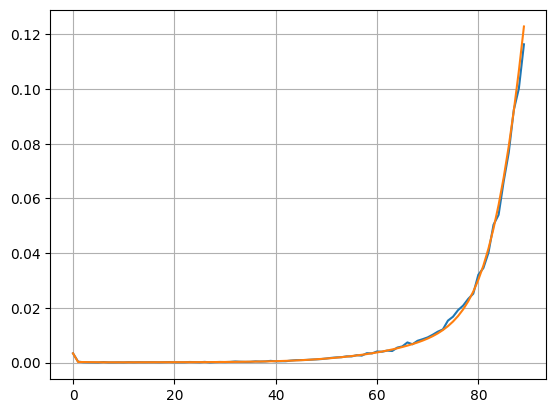

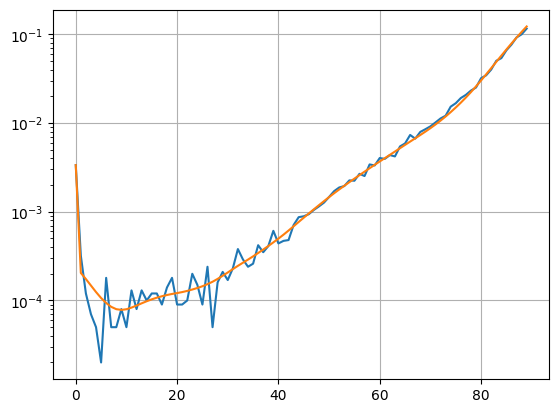

In [26]:
import numpy as np
import scipy.sparse as sparse
from scipy.sparse.linalg import splu


def speyediff(N, d, format='csc'):
    """
    (utility function)
    Construct a d-th order sparse difference matrix based on 
    an initial N x N identity matrix
    
    Final matrix (N-d) x N
    """
    
    assert not (d < 0), "d must be non negative"
    shape     = (N-d, N)
    diagonals = np.zeros(2*d + 1)
    diagonals[d] = 1.
    for i in range(d):
        diff = diagonals[:-1] - diagonals[1:]
        diagonals = diff
    offsets = np.arange(d+1)
    spmat = sparse.diags(diagonals, offsets, shape, format=format)
    return spmat


def whittaker_smooth(y, lmbd, d = 2):
    """
    Implementation of the Whittaker smoothing algorithm,
    based on the work by Eilers [1].
    [1] P. H. C. Eilers, "A perfect smoother", Anal. Chem. 2003, (75), 3631-3636
    
    The larger 'lmbd', the smoother the data.
    For smoothing of a complete data series, sampled at equal intervals
    This implementation uses sparse matrices enabling high-speed processing
    of large input vectors
    
    ---------
    
    Arguments :
    
    y       : vector containing raw data
    lmbd    : parameter for the smoothing algorithm (roughness penalty)
    d       : order of the smoothing 
    
    ---------
    Returns :
    
    z       : vector of the smoothed data.
    """

    m = len(y)
    E = sparse.eye(m, format='csc')
    D = speyediff(m, d, format='csc')
    coefmat = E + lmbd * D.conj().T.dot(D)
    z = splu(coefmat).solve(y)
    return z   

y = np.zeros(110)
qx2015 = np.zeros((3,110))

t=2015

for gender in range(2):
    y[0]= QxData[(gender,t,1)][0]
    for i in range(1,110):
        y[i]=QxData[(gender,t,i)][0]
        lam = 100
    y2 = whittaker_smooth(y, lam)
    y2[0]=QxData[(gender,t,0)][0]
    for i in range(110):
        qx2015[0, i]= i
        qx2015[gender+1,i]= min(1, max(0.0,y2[i]))
    y[0]= QxData[(gender,t,0)][0]

strOut = "Results qx \n"
strOut += "%-5s  %10s  %10s \n" %("Age","Male (qx)","Female(qx)")

for i in range(0,110,10):
    strOut+= "%5d  %10.4f  %10.4f \n" %(i,qx2015[1,i],qx2015[2,i])

print("Females plot")
    
plt.figure(1)
x=range(90)
plt.plot(x,y[x],x,y2[x])
plt.grid(True)

plt.figure(2)
x=range(90)
plt.semilogy(x,y[x],x,y2[x])
plt.grid(True)

print(strOut)

Females plot
Results qx 
Age    Male (lam)  Female(lam) 
    0     -0.0433     -0.0413 
   10     -0.0457     -0.0385 
   20     -0.0361     -0.0309 
   30     -0.0273     -0.0243 
   40     -0.0217     -0.0204 
   50     -0.0226     -0.0174 
   60     -0.0243     -0.0162 
   70     -0.0248     -0.0206 
   80     -0.0189     -0.0205 
   90     -0.0081     -0.0102 
  100     -0.0009     -0.0018 



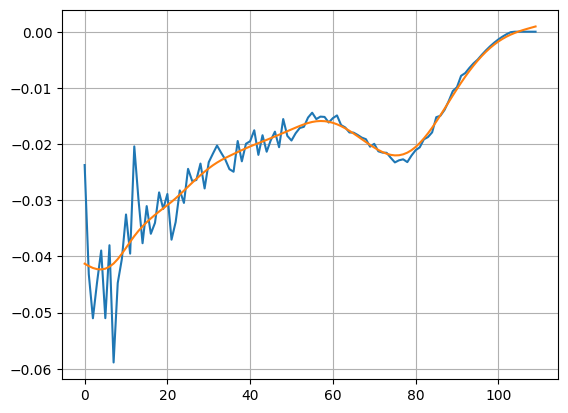

In [27]:
from scipy import stats
T=range(2015-40,2015)
lamdaraw = np.zeros(110)
lam2015 = np.zeros((3,110))
for gender in range(2):
    for i in range(110):
        myt = []
        qxlog = []
        for t in T:
            myt.append(t)
            qxlog.append(np.log(max(0.000001,QxData[(gender,t,i)][0])))
        slope, intercept, r_value, p_value, std_err = stats.linregress(myt,qxlog)
        lamdaraw[i] = min(slope,0)

    lam = 250
    
    mylambda = whittaker_smooth(lamdaraw, lam)
    for i in range(110):
        lam2015[0, i]= i
        lam2015[gender+1,i]=mylambda[i]
        if i>100: lam2015[gender+1,i]=0.

strOut = "Results qx \n"
strOut += "%-5s  %10s  %10s \n" %("Age","Male (lam)","Female(lam)")

for i in range(0,110,10):
    strOut+= "%5d  %10.4f  %10.4f \n" %(i,lam2015[1,i],lam2015[2,i])

print("Females plot")
    
    
plt.figure(3)
plt.plot(range(110),lamdaraw,range(110),mylambda)
plt.grid(True)

print(strOut)

Results ex(Raw) 
Age    Male (ex 2020)  Female(ex 2020) 
    0     80.7012     84.8926 
   10     71.1471     75.2532 
   20     61.2800     65.3327 
   30     51.5632     55.4153 
   40     41.8298     45.5823 
   50     32.3275     35.9116 
   60     23.3575     26.6297 
   70     15.3304     17.8917 
   80      8.4795     10.0542 
   90      3.7588      4.3912 
  100      1.7787      1.8922 

Results ex 
Age    Male (ex 2020)  Female(ex 2020) 
    0     90.5689     92.9987 
   10     80.0228     82.5810 
   20     69.0925     71.8316 
   30     58.2076     61.0320 
   40     47.2426     50.2327 
   50     36.4223     39.5671 
   60     26.1392     29.2670 
   70     16.8483     19.5056 
   80      8.9717     10.6748 
   90      3.8791      4.5256 
  100      1.8068      1.9287 



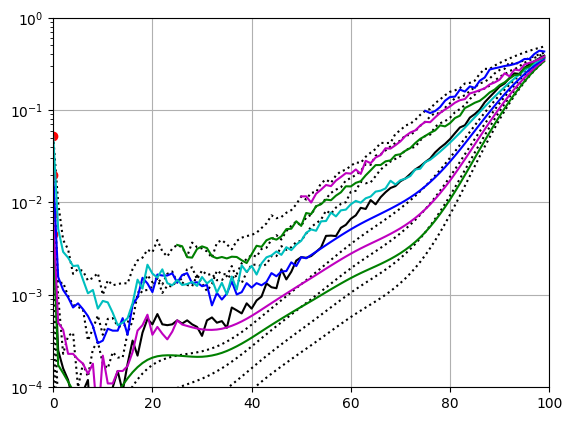

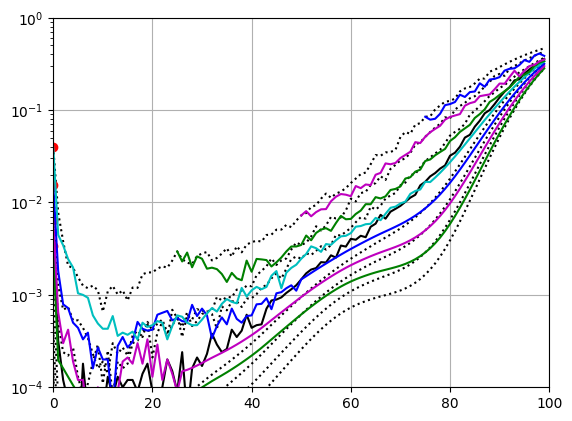

<Figure size 640x480 with 0 Axes>

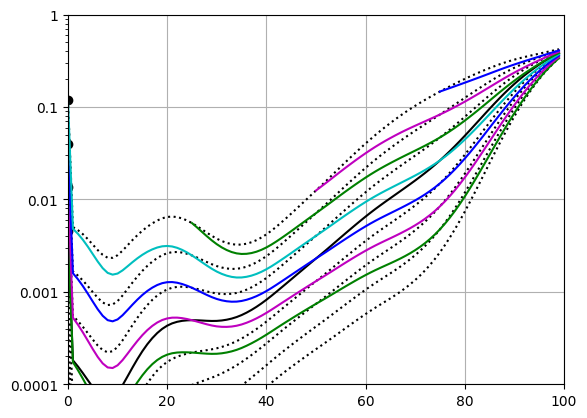

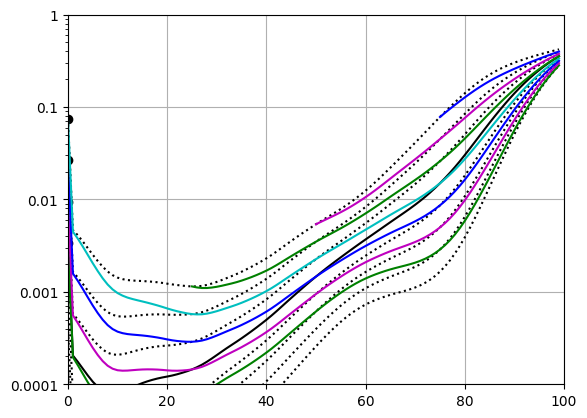

In [28]:
import matplotlib.ticker as ticker

@ticker.FuncFormatter
def major_formatter(y, pos):
    #return f'[{x:6.4f}]'
    return("%6.4f"%(y))

def qxProj(gender,x,t,t0=2015):
    qxout = qx2015[gender+1,x] * np.exp((t-t0)*lam2015[gender+1,x])
    return(qxout)

def exProj(gender,x,t,t0=2015,omega=110,qx=qxProj):
    ex= 0
    for i in range(omega,x-1,-1):
        try:
            ex = 1 + (1-qx(gender,i,t+i-x,t0=t0))*ex
        except:
            ex = 0
    ex-=0.5
    return(ex)

def qxRaw(gender,x,t,t0=2015):
    try:
        return(QxData[gender,min(t,t0),x][0])
    except:
        return(1)

def QxTotal(gender,x,t,t0=2015):
    if( t <= t0): return(qxRaw(gender,x,t,t0=t0))
    return(qxProj(gender,x,t,t0=t0))
    

T     = [1940,1965,1990,2015,2040,2065,2090,2115]
StyleT = ["k:","k:","k:","k-","k:",'k:','k:','k:']
Ages  = [-75,-50,-25,0,25,50,75]
StyleA= ["g-","m-","b-","c-","g-","m-","b-"]
MaxAge = 105

def DoFigure(gender,T,StyleT,Ages,StyleA,xl=0,xu=100, figNr=1,plotter=plt.semilogy,figName="EaxRaw.pdf"):
    plt.figure(figNr)
    x = range(xl,xu)
    for it in range(len(T)):
        t = T[it]
        y = []
        for i in x:
            y.append(QxTotal(gender,i,t))
        plotter(x,y,StyleT[it])
    for ix0 in range(len(Ages)):
        x0 = Ages[ix0]
        x =[]
        y =[]
        for t in range(1940,max(T)+1):
            xTemp = x0 + (t-1940)
            if xTemp<0 or xTemp >= xu: continue
            x.append(xTemp)
            y.append(QxTotal(gender,xTemp,t))
            if xTemp == 0: plotter(x,y,"ro")
        plotter(x,y,StyleA[ix0])
        plt.axis([xl,xu, 0.0001,1])
    plt.grid(True)
    plt.savefig(figName,dpi=300)
    

def DoFigure2(gender,T,StyleT,Ages,StyleA,xl=0,xu=100, figNr=11,plotter=plt.semilogy,figName="EaxSmooth.pdf",MyFunction=qxProj):
    fig = plt.figure(figNr)
    fig1, ax = plt.subplots(1, 1)
    x = range(xl,xu)
    for it in range(len(T)):
        t = T[it]
        y = []
        for i in x:
            y.append(MyFunction(gender,i,t))
        plotter(x,y,StyleT[it])
    for ix0 in range(len(Ages)):
        x0 = Ages[ix0]
        x =[]
        y =[]
        for t in range(1940,max(T)+1):
            xTemp = x0 + (t-1940)
            if xTemp<0 or xTemp >= xu: continue
            x.append(xTemp)
            y.append(MyFunction(gender,xTemp,t))
            if xTemp == 0: plotter(x,y,"ko")
        plotter(x,y,StyleA[ix0])
        plt.axis([xl,xu, 0.0001,1])
    plt.grid(True)
    #ax.xaxis.set_major_formatter(major_formatter)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:g}'.format(y)))
    plt.savefig(figName,dpi=300)
    return(ax)
    
DoFigure(0,T,StyleT,Ages,StyleA)
DoFigure(1,T,StyleT,Ages,StyleA,figNr=2)
DoFigure2(0,T,StyleT,Ages,StyleA)
DoFigure2(1,T,StyleT,Ages,StyleA,figNr=12)

strOut = "Results ex(Raw) \n"
strOut += "%-5s  %10s  %10s \n" %("Age","Male (ex 2020)","Female(ex 2020)")

for i in range(0,110,10):
    strOut+= "%5d  %10.4f  %10.4f \n" %(i,exProj(0,i,2015,qx=qxRaw),exProj(1,i,2015,qx=qxRaw))

print(strOut)
    
strOut = "Results ex \n"
strOut += "%-5s  %10s  %10s \n" %("Age","Male (ex 2020)","Female(ex 2020)")

for i in range(0,110,10):
    strOut+= "%5d  %10.4f  %10.4f \n" %(i,exProj(0,i,2020),exProj(1,i,2020))

print(strOut)


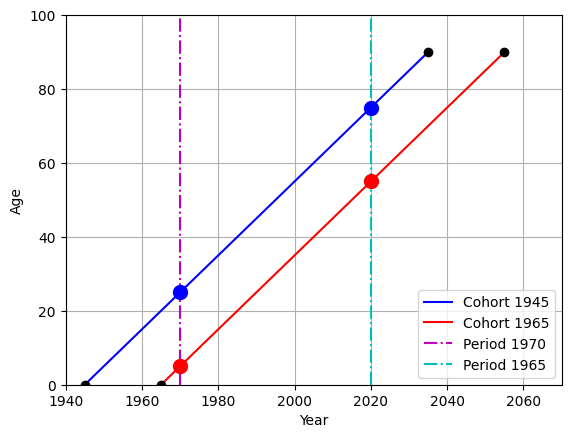

In [29]:
x=range(0,101)
t=range(1950,2051)
gd0 = 1945
gd1 = 1965
x1=[]
y1=[]
x2=[]
y2=[]
x3=[]
y3=[]
x4=[]
y4=[]
for i in range(90):
    x1.append(gd0+i)
    x2.append(gd1+i)
    y1.append(i)
    y2.append(i)
for i in range(101):
    x3.append(1970)
    y3.append(i)
    x4.append(2020)
    y4.append(i)
    
plt.plot(x1,y1,"b-")
plt.plot(x2,y2,"r-")
plt.plot(x3,y3,"m-.")
plt.plot(x4,y4,"c-.")
plt.grid(True)
xTemp=[gd0, gd0+90]
yTemp=[0,90]
plt.plot(xTemp,yTemp,"ko")
xTemp=[gd1, gd1+90]
plt.plot(xTemp,yTemp,"ko")

xTemp = [1970,1970,2020,2020]
yTemp = [25,5,75,55]
Markers = ["bo","ro","bo","ro"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(xTemp[k])
    yyT.append(yTemp[k])
    plt.plot(xxT,yyT,Markers[k],markersize=10)
plt.axis([1940,2070,0,100])
plt.xlabel("Year")
plt.ylabel("Age")
plt.legend(["Cohort 1945","Cohort 1965","Period 1970","Period 1965"])
plt.savefig("paul1.pdf")




    

<Figure size 640x480 with 0 Axes>

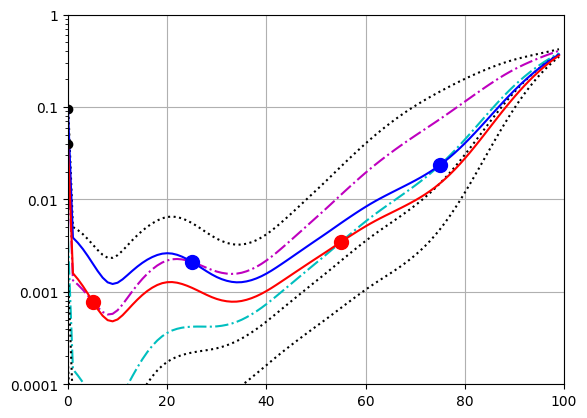

In [30]:
T     = [1940,1970,2020,2040,2090]
StyleT = ["k:","m-.","c-.","k:","k:",'k:','k:','k:']
Ages2  = [-5,-25]
StyleA= ["b-","r-","g-","c-","g-","m-","b-"]
MaxAge = 105

ax = DoFigure2(0,T,StyleT,Ages2,StyleA)

xTemp = [1970,1970,2020,2020]
yTemp = [25,5,75,55]
Markers = ["bo","ro","bo","ro"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(yTemp[k])
    yyT.append(qxProj(0,yTemp[k],xTemp[k],t0=2015))
    #print(xxT,yyT)
    plt.semilogy(xxT,yyT,Markers[k],markersize=10)

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:g}'.format(y)))    
plt.savefig("paul2.pdf")

<Figure size 640x480 with 0 Axes>

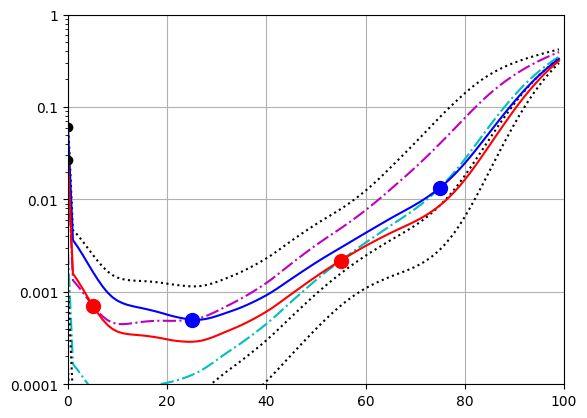

In [31]:
ax = DoFigure2(1,T,StyleT,Ages2,StyleA)
xTemp = [1970,1970,2020,2020]
yTemp = [25,5,75,55]
Markers = ["bo","ro","bo","ro"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(yTemp[k])
    yyT.append(qxProj(1,yTemp[k],xTemp[k],t0=2015))
    #print(xxT,yyT)
    plt.semilogy(xxT,yyT,Markers[k],markersize=10)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:g}'.format(y)))       
plt.savefig("paul3.pdf")

(np.float64(0.0), np.float64(100.0), np.float64(0.0), np.float64(120.0))

<Figure size 640x480 with 0 Axes>

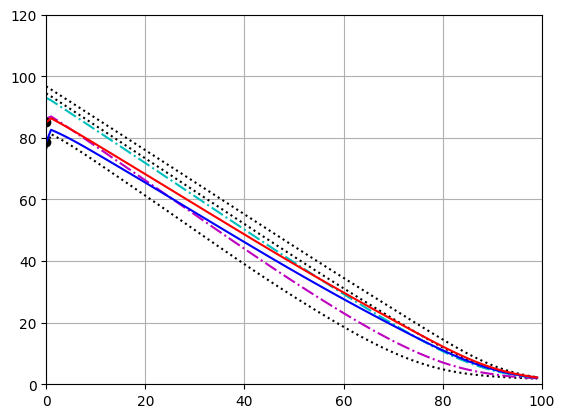

In [32]:
ax = DoFigure2(1,T,StyleT,Ages2,StyleA,MyFunction=exProj,plotter=plt.plot)
plt.axis([0,100, 0.0,120])

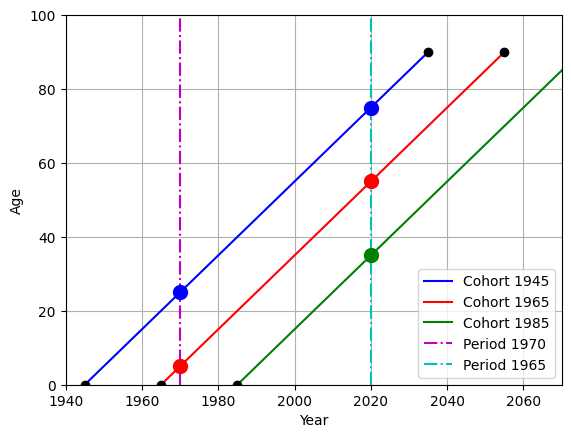

In [33]:
x=range(0,101)
t=range(1950,2051)
gd0 = 1945
gd1 = 1965
gd2 = 1985
x1=[]
y1=[]
x2=[]
y2=[]
x2a=[]
y2a=[]
x3=[]
y3=[]
x4=[]
y4=[]
for i in range(90):
    x1.append(gd0+i)
    x2.append(gd1+i)
    x2a.append(gd2+i)
   
    y1.append(i)
    y2.append(i)
    y2a.append(i)
for i in range(101):
    x3.append(1970)
    y3.append(i)
    x4.append(2020)
    y4.append(i)
    
plt.plot(x1,y1,"b-")
plt.plot(x2,y2,"r-")
plt.plot(x2a,y2a,"g-")
plt.plot(x3,y3,"m-.")
plt.plot(x4,y4,"c-.")
plt.grid(True)
xTemp=[gd0, gd0+90]
yTemp=[0,90]
plt.plot(xTemp,yTemp,"ko")
xTemp=[gd1, gd1+90]
plt.plot(xTemp,yTemp,"ko")
xTemp=[gd2, gd2+90]
yTemp=[0,90]
plt.plot(xTemp,yTemp,"ko")

xTemp = [1970,1970,2020,2020,2020]
yTemp = [25,5,75,55,35]
Markers = ["bo","ro","bo","ro","go"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(xTemp[k])
    yyT.append(yTemp[k])
    plt.plot(xxT,yyT,Markers[k],markersize=10)
plt.axis([1940,2070,0,100])
plt.xlabel("Year")
plt.ylabel("Age")
plt.legend(["Cohort 1945","Cohort 1965","Cohort 1985","Period 1970","Period 1965"])
plt.savefig("paul1a.pdf")



<Figure size 640x480 with 0 Axes>

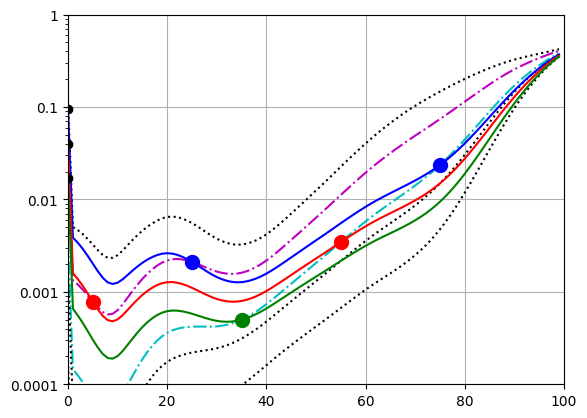

In [34]:
T     = [1940,1970,2020,2040,2090]
StyleT = ["k:","m-.","c-.","k:","k:",'k:','k:','k:']
Ages2  = [-5,-25,-45]
StyleA= ["b-","r-","g-","c-","g-","m-","b-"]
MaxAge = 105

ax = DoFigure2(0,T,StyleT,Ages2,StyleA)

xTemp = [1970,1970,2020,2020,2020]
yTemp = [25,5,75,55,35]
Markers = ["bo","ro","bo","ro","go"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(yTemp[k])
    yyT.append(qxProj(0,yTemp[k],xTemp[k],t0=2015))
    #print(xxT,yyT)
    plt.semilogy(xxT,yyT,Markers[k],markersize=10)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:g}'.format(y)))      
plt.savefig("paul2a.pdf")

<Figure size 640x480 with 0 Axes>

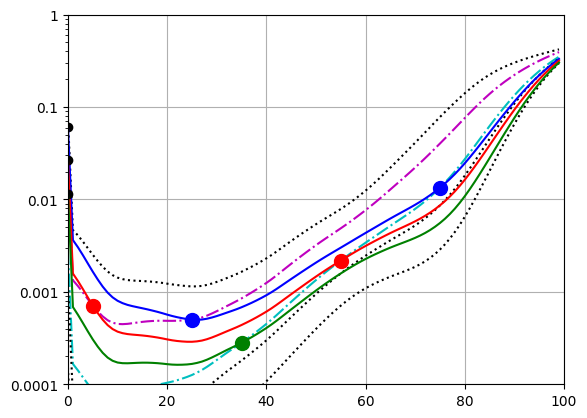

In [35]:
T     = [1940,1970,2020,2040,2090]
StyleT = ["k:","m-.","c-.","k:","k:",'k:','k:','k:']
Ages2  = [-5,-25,-45]
StyleA= ["b-","r-","g-","c-","g-","m-","b-"]
MaxAge = 105

ax= DoFigure2(1,T,StyleT,Ages2,StyleA)

xTemp = [1970,1970,2020,2020,2020]
yTemp = [25,5,75,55,35]
Markers = ["bo","ro","bo","ro","go"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(yTemp[k])
    yyT.append(qxProj(1,yTemp[k],xTemp[k],t0=2015))
    #print(xxT,yyT)
    plt.semilogy(xxT,yyT,Markers[k],markersize=10)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:g}'.format(y)))      
plt.savefig("paul3a.pdf")

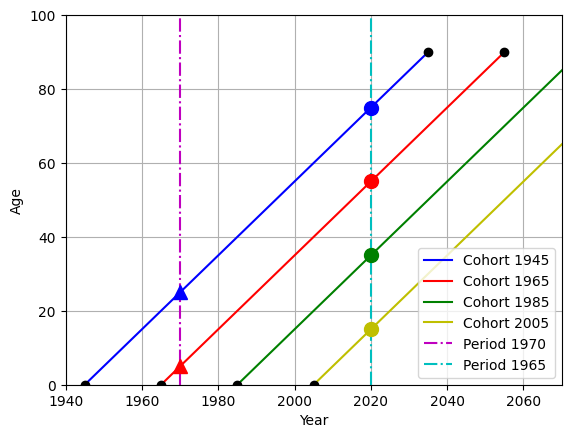

In [36]:
x=range(0,101)
t=range(1950,2051)
gd0 = 1945
gd1 = 1965
gd2 = 1985
gd3 = 2005
x1=[]
y1=[]
x2=[]
y2=[]
x2a=[]
y2a=[]
x2b=[]
y2b=[]
x3=[]
y3=[]
x4=[]
y4=[]
for i in range(90):
    x1.append(gd0+i)
    x2.append(gd1+i)
    x2a.append(gd2+i)
    x2b.append(gd3+i) 
    y1.append(i)
    y2.append(i)
    y2a.append(i)
    y2b.append(i)
    
for i in range(101):
    x3.append(1970)
    y3.append(i)
    x4.append(2020)
    y4.append(i)
    
plt.plot(x1,y1,"b-")
plt.plot(x2,y2,"r-")
plt.plot(x2a,y2a,"g-")
plt.plot(x2b,y2b,"y-")
plt.plot(x3,y3,"m-.")
plt.plot(x4,y4,"c-.")
plt.grid(True)
xTemp=[gd0, gd0+90]
yTemp=[0,90]
plt.plot(xTemp,yTemp,"ko")
xTemp=[gd1, gd1+90]
plt.plot(xTemp,yTemp,"ko")
xTemp=[gd2, gd2+90]
yTemp=[0,90]
plt.plot(xTemp,yTemp,"ko")
xTemp=[gd3, gd3+90]
yTemp=[0,90]
plt.plot(xTemp,yTemp,"ko")

xTemp = [1970,1970,2020,2020,2020,2020]
yTemp = [25,5,75,55,35,15]
Markers = ["b^","r^","bo","ro","go","yo"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(xTemp[k])
    yyT.append(yTemp[k])
    plt.plot(xxT,yyT,Markers[k],markersize=10)
plt.axis([1940,2070,0,100])
plt.xlabel("Year")
plt.ylabel("Age")
plt.legend(["Cohort 1945","Cohort 1965","Cohort 1985","Cohort 2005","Period 1970","Period 1965"])
plt.savefig("paul1b.pdf")

<Figure size 640x480 with 0 Axes>

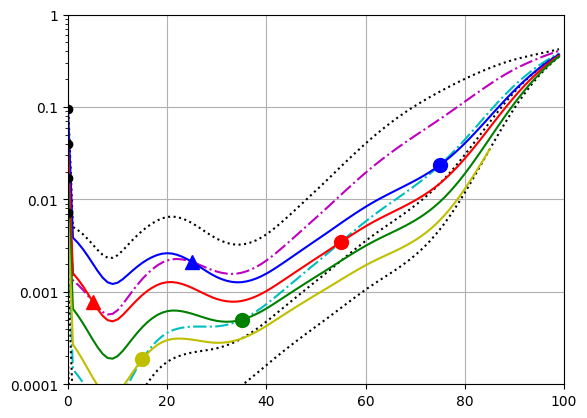

In [37]:
T     = [1940,1970,2020,2040,2090]
StyleT = ["k:","m-.","c-.","k:","k:",'k:','k:','k:']
Ages2  = [-5,-25,-45,-65]
StyleA= ["b-","r-","g-","y-","g-","m-","b-"]
MaxAge = 105

ax=DoFigure2(0,T,StyleT,Ages2,StyleA)

xTemp = [1970,1970,2020,2020,2020,2020]
yTemp = [25,5,75,55,35,15]
Markers = ["b^","r^","bo","ro","go","yo"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(yTemp[k])
    yyT.append(qxProj(0,yTemp[k],xTemp[k],t0=2015))
    #print(xxT,yyT)
    plt.semilogy(xxT,yyT,Markers[k],markersize=10)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:g}'.format(y)))       
plt.savefig("paul2b.pdf")

<Figure size 640x480 with 0 Axes>

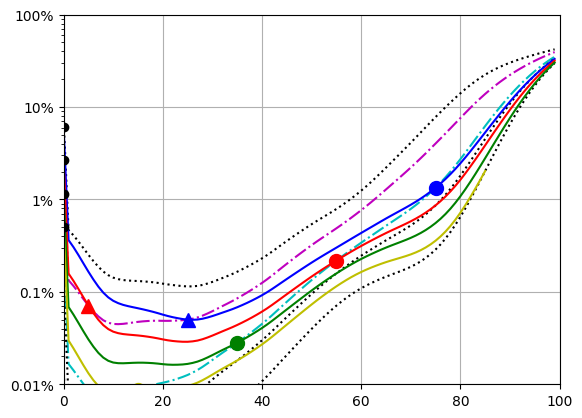

In [38]:
T     = [1940,1970,2020,2040,2090]
StyleT = ["k:","m-.","c-.","k:","k:",'k:','k:','k:']
Ages2  = [-5,-25,-45,-65]
StyleA= ["b-","r-","g-","y-","g-","m-","b-"]
MaxAge = 105

ax= DoFigure2(1,T,StyleT,Ages2,StyleA)

xTemp = [1970,1970,2020,2020,2020,2020]
yTemp = [25,5,75,55,35,15]
Markers = ["b^","r^","bo","ro","go","yo"]
for k in range(len(xTemp)):
    xxT =[]
    yyT = []
    xxT.append(yTemp[k])
    yyT.append(qxProj(1,yTemp[k],xTemp[k],t0=2015))
    #print(xxT,yyT)
    plt.semilogy(xxT,yyT,Markers[k],markersize=10)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:g}%'.format(100*y)))       
plt.savefig("paul3b.pdf")

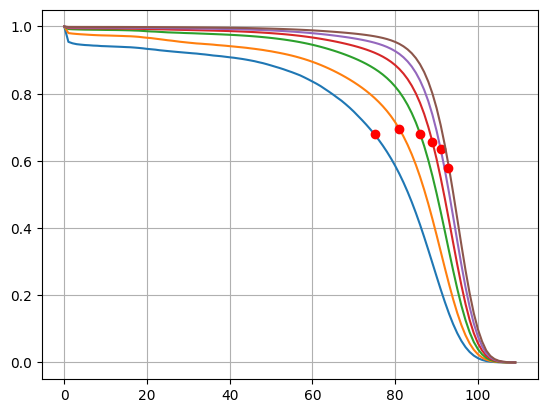

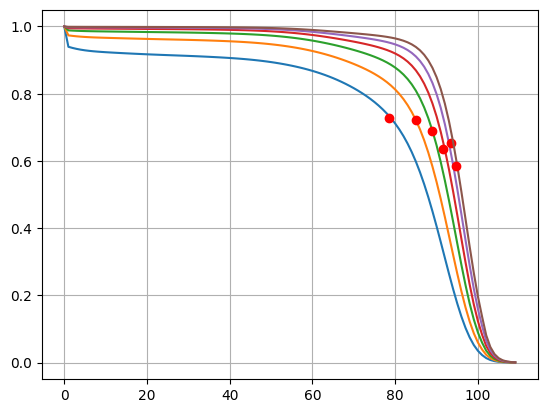

In [39]:
def dGet_tPx(gender,t,n=110,startage=0):
    res = []
    lx = 1.
    for i in range(startage, n):
        res.append(lx)
        lx *= 1-QxTotal(gender,i,t+i)
    return(res)

T = [1945, 1965, 1985, 2005,2025,2045]
plt.figure(1)
for t in T:
    tt = dGet_tPx(0,t)
    plt.plot(range(110), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([ex],[tt[index]],"ro")
plt.grid(True)

def dGet_tPx_P(gender,t,n=110):
    res = []
    lx = 1.
    for i in range(n):
        res.append(lx)
        lx *= 1-qxProj(gender,i,t+i)
    return(res)


plt.figure(2)
for t in T:
    tt = dGet_tPx_P(1,t)
    plt.plot(range(110), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([ex],[tt[index]],"ro")
plt.grid(True)

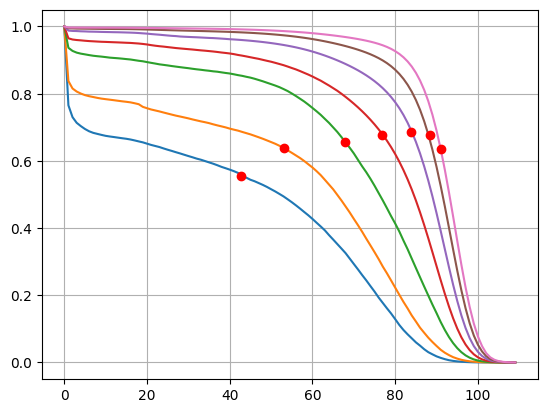

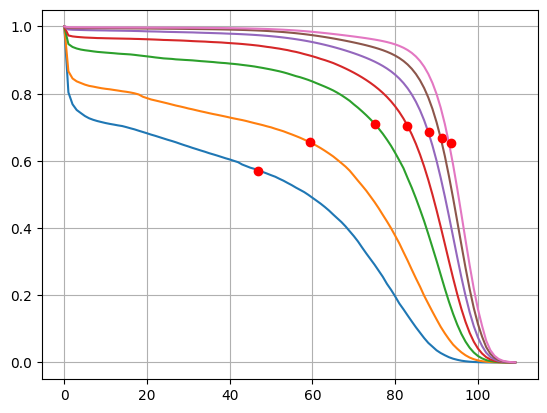

In [40]:
T = [1876, 1900, 1925, 1950, 1975, 2000,2025]
plt.figure(1)
for t in T:
    tt = dGet_tPx(0,t)
    plt.plot(range(110), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([ex],[tt[index]],"ro")
plt.grid(True)

plt.figure(2)
for t in T:
    tt = dGet_tPx(1,t)
    plt.plot(range(110), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([ex],[tt[index]],"ro")
plt.grid(True)



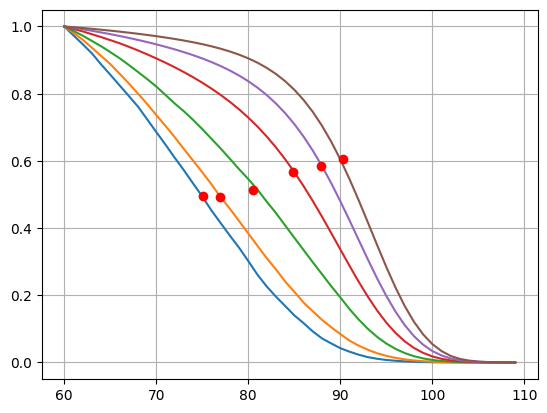

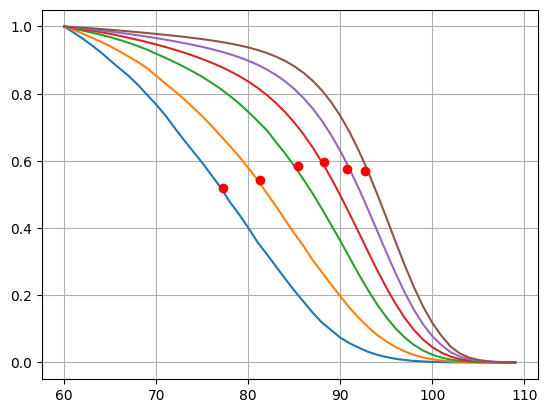

In [41]:
T = [1876, 1900, 1925, 1950, 1975, 2000]
plt.figure(1)
for t in T:
    tt = dGet_tPx(0,t,startage=60)
    plt.plot(range(60,60+len(tt)), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([60+ex],[tt[index]],"ro")
plt.grid(True)

plt.figure(2)
for t in T:
    tt = dGet_tPx(1,t,startage=60)
    plt.plot(range(60,60+len(tt)), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([60+ex],[tt[index]],"ro")
plt.grid(True)


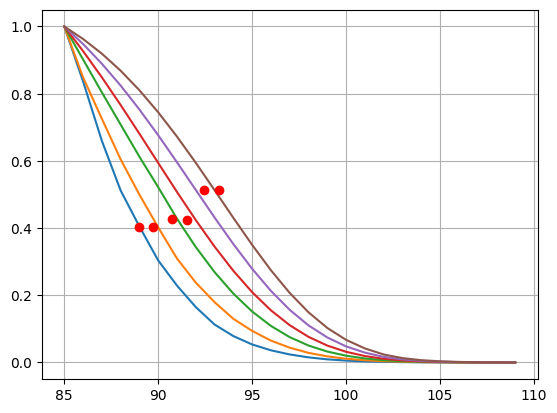

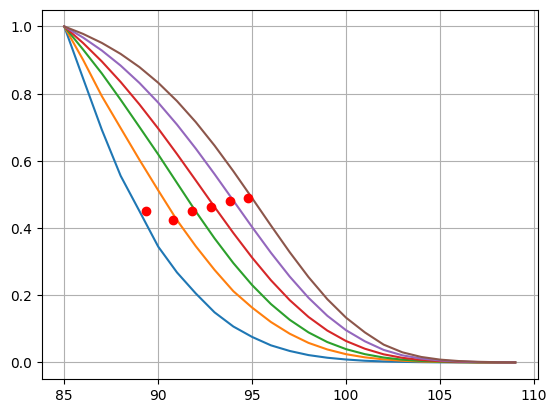

In [42]:
plt.figure(1)
for t in T:
    tt = dGet_tPx(0,t,startage=85)
    plt.plot(range(85,85+len(tt)), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([85+ex],[tt[index]],"ro")
plt.grid(True)

plt.figure(2)
for t in T:
    tt = dGet_tPx(1,t,startage=85)
    plt.plot(range(85,85+len(tt)), tt)
    ex = sum(tt) - 0.5
    index = int(ex+0.5)
    plt.plot([85+ex],[tt[index]],"ro")
plt.grid(True)
